# Benchmark Structure Prediction Methods

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences['fold'] = sequences['fold'].astype(str)

## Antigen Specificity

In [3]:
af3_confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
af3_confidence_scores['model'] = 'AlphaFold3'

In [4]:
af3_confidence_scores['top_rank'] = False
af3_confidence_scores.loc[af3_confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [5]:
chai_confidence_scores = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_1500.csv')
chai_confidence_scores['model'] = 'Chai-1'

In [6]:
chai_confidence_scores['top_rank'] = False
chai_confidence_scores.loc[chai_confidence_scores.groupby('name')['aggregate_score'].idxmax(), 'top_rank'] = True

In [7]:
confidence_scores = pd.concat([af3_confidence_scores, chai_confidence_scores]).reset_index(drop=True)

In [8]:
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

### Overall

In [9]:
roc_aucs = confidence_scores.groupby('model').apply(
    lambda group: 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), include_groups=False
)
roc_aucs.name = 'roc_auc'

roc_aucs_top_rank = (
    confidence_scores.query('top_rank')
    .groupby('model')
    .apply(lambda group: 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), include_groups=False)
)
roc_aucs_top_rank.name = 'roc_auc'

print('All\n', roc_aucs, '\n\n', 'Top Rank\n', roc_aucs_top_rank)

All
 model
AlphaFold3    0.600333
Chai-1        0.612470
Name: roc_auc, dtype: float64 

 Top Rank
 model
AlphaFold3    0.601385
Chai-1        0.610668
Name: roc_auc, dtype: float64


### Bootstrap

In [10]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500

names = confidence_scores['name'].unique()
rng = np.random.default_rng(123)

samples_roc_aucs = []
samples_roc_aucs_top_rank = []
for sample_num in range(1, NUM_SAMPLES + 1):
    sample_names = rng.choice(names, SAMPLE_SIZE)

    sample = confidence_scores[confidence_scores['name'].isin(sample_names)]

    sample_roc_aucs = sample.groupby('model').apply(
        lambda group: 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), include_groups=False
    )
    sample_roc_aucs.name = 'roc_auc'
    sample_roc_aucs = sample_roc_aucs.reset_index()

    sample_roc_aucs['sample_num'] = sample_num

    samples_roc_aucs.append(sample_roc_aucs)

    sample_roc_aucs_top_rank = (
        sample.query('top_rank')
        .groupby('model')
        .apply(lambda group: 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), include_groups=False)
    )
    sample_roc_aucs_top_rank.name = 'roc_auc'
    sample_roc_aucs_top_rank = sample_roc_aucs_top_rank.reset_index()

    sample_roc_aucs_top_rank['sample_num'] = sample_num

    samples_roc_aucs_top_rank.append(sample_roc_aucs_top_rank)

samples_roc_aucs = pd.concat(samples_roc_aucs).reset_index(drop=True)
samples_roc_aucs_top_rank = pd.concat(samples_roc_aucs_top_rank).reset_index(drop=True)

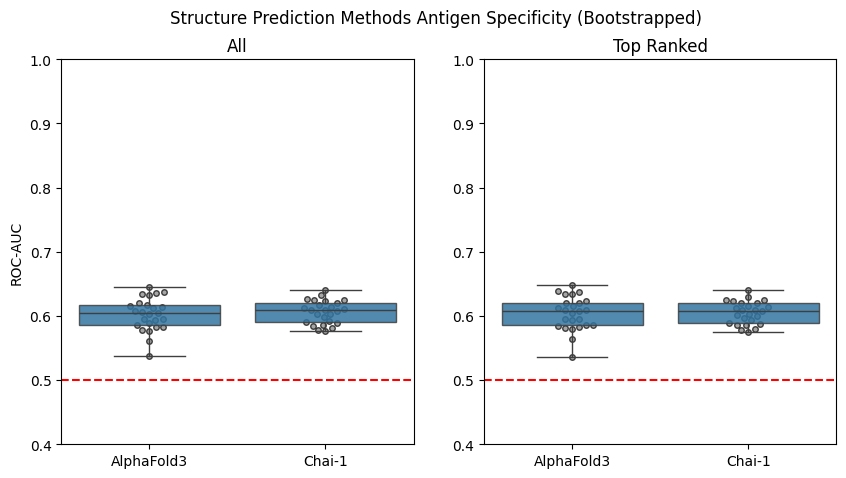

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

fig.suptitle('Structure Prediction Methods Antigen Specificity (Bootstrapped)')

for i, (ax, title, data) in enumerate(
    zip(axes, ('All', 'Top Ranked'), (samples_roc_aucs, samples_roc_aucs_top_rank), strict=True)
):
    sns.swarmplot(
        data,
        x='model',
        y='roc_auc',
        color='grey',
        zorder=1,
        marker='o',
        size=4,
        edgecolor='black',
        linewidth=1,
        alpha=0.70,
        ax=ax,
    )
    sns.boxplot(data, x='model', y='roc_auc', boxprops={'alpha': 0.85}, ax=ax)

    ax.axhline(0.5, color='r', linestyle='dashed')

    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylim(0.4, 1.0)

    if i == 0:
        ax.set_ylabel('ROC-AUC')

    else:
        ax.set_ylabel('')

plt.show()

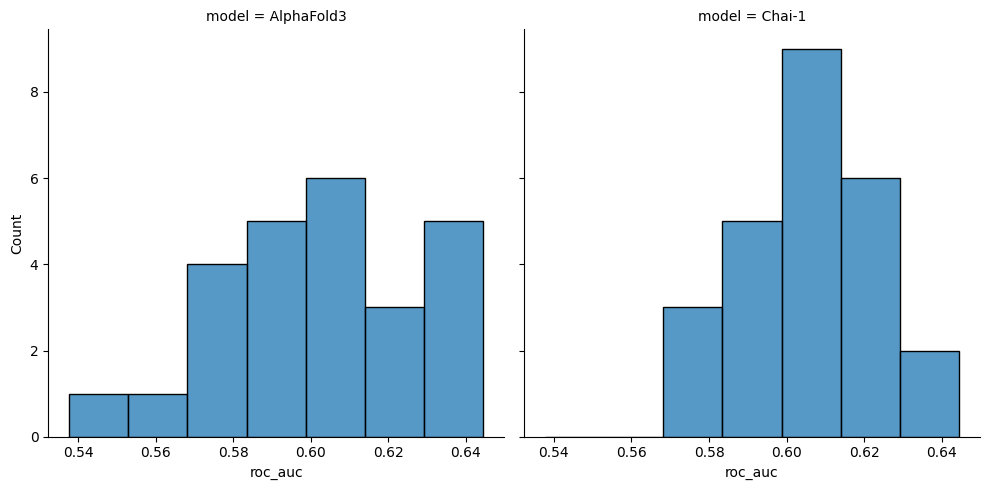

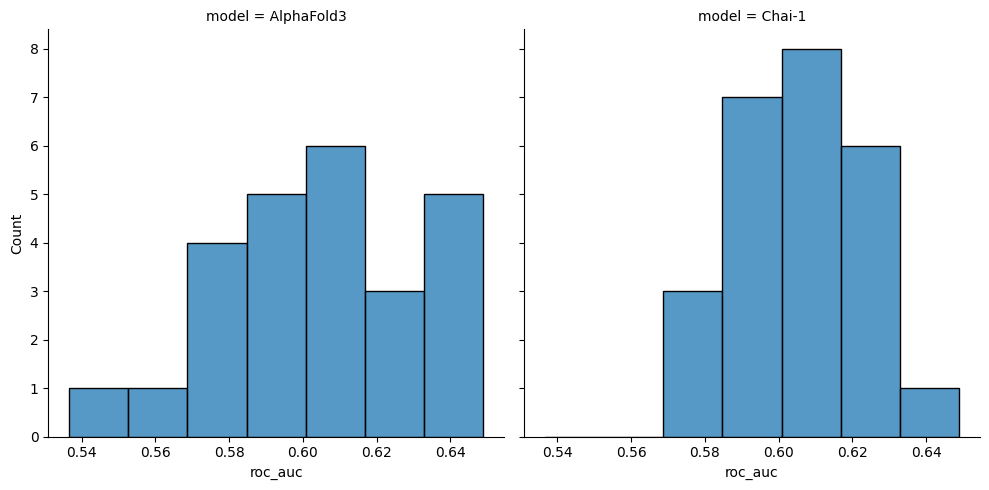

In [12]:
sns.displot(samples_roc_aucs, col='model', x='roc_auc', kind='hist')
sns.displot(samples_roc_aucs_top_rank, col='model', x='roc_auc', kind='hist')

plt.show()

In [13]:
for title, data in zip(('All', 'Top Ranked'), (samples_roc_aucs, samples_roc_aucs_top_rank), strict=True):
    print(title)

    ipy_display.display(pg.anova(data, dv='roc_auc', between='model'))

    groups = list(data.groupby('model')['roc_auc'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,1,48,0.384119,0.538338,0.007939


,group1,group2,stat,p_val,signficant
0,AlphaFold3,Chai-1,-0.619773,0.538338,False



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,1,48,0.016934,0.897007,0.000353


,group1,group2,stat,p_val,signficant
0,AlphaFold3,Chai-1,-0.13013,0.897007,False


### By Fold

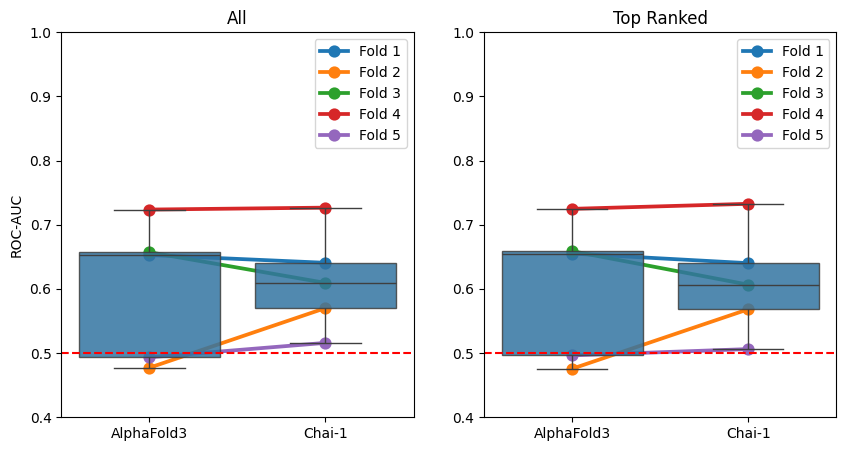

In [14]:
roc_aucs_by_fold = confidence_scores.groupby(['model', 'fold']).apply(
    lambda group: 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), include_groups=False
)
roc_aucs_by_fold.name = 'roc_auc'
roc_aucs_by_fold = roc_aucs_by_fold.reset_index()

roc_aucs_by_fold_top_rank = (
    confidence_scores.query('top_rank')
    .groupby(['model', 'fold'])
    .apply(lambda group: 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']), include_groups=False)
)
roc_aucs_by_fold_top_rank.name = 'roc_auc'
roc_aucs_by_fold_top_rank = roc_aucs_by_fold_top_rank.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for i, (ax, title, data) in enumerate(
    zip(axes, ('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True)
):
    sns.pointplot(data, x='model', y='roc_auc', hue='fold', ax=ax)
    sns.boxplot(data, x='model', y='roc_auc', boxprops={'alpha': 0.85}, ax=ax)

    ax.axhline(0.5, color='r', linestyle='dashed')

    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylim(0.4, 1.0)

    handles, labels = ax.get_legend_handles_labels()
    new_labels = [f'Fold {label}' for label in labels]
    ax.legend(handles, new_labels)

    if i == 0:
        ax.set_ylabel('ROC-AUC')

    else:
        ax.set_ylabel('')

plt.show()

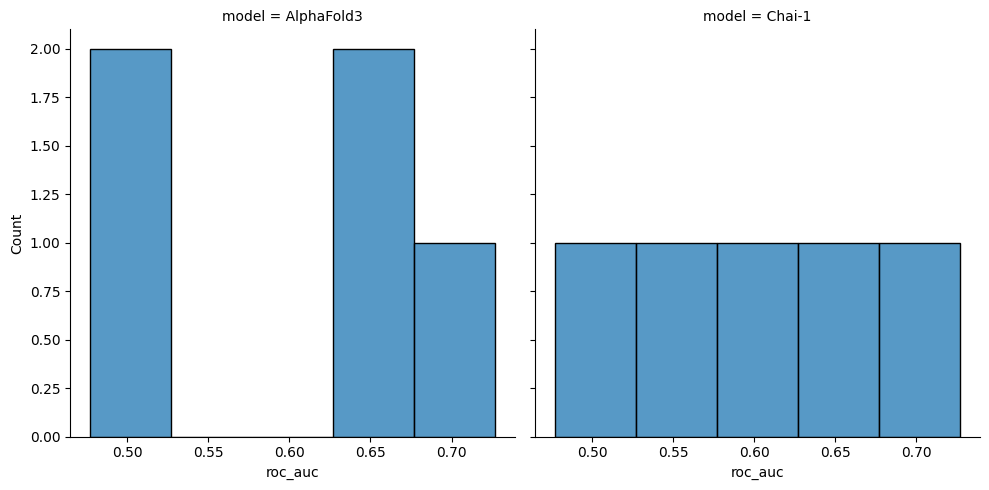

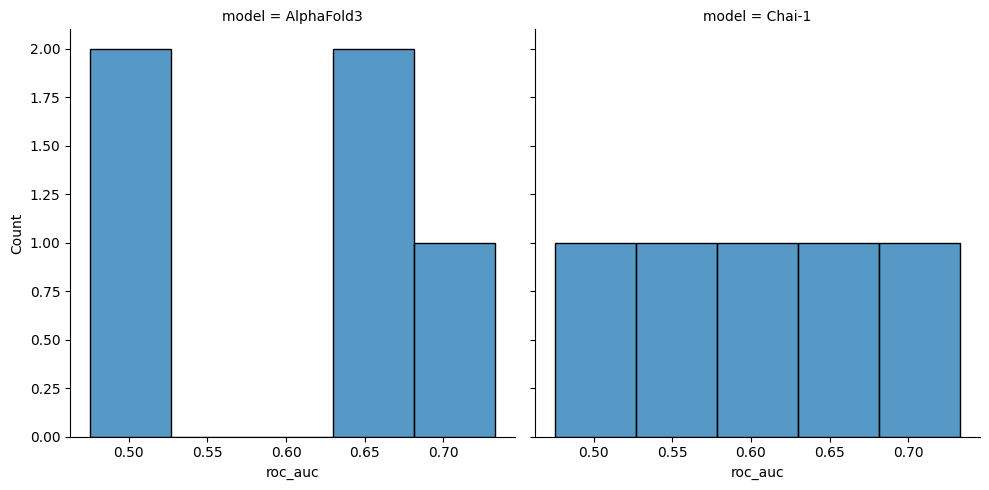

In [15]:
sns.displot(roc_aucs_by_fold, col='model', x='roc_auc', kind='hist')
sns.displot(roc_aucs_by_fold_top_rank, col='model', x='roc_auc', kind='hist')

plt.show()

In [16]:
for title, data in zip(('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True):
    print(title)

    ipy_display.display(pg.friedman(data, dv='roc_auc', within='model', subject='fold', method='f'))

    groups = list(data.set_index('fold').groupby('model')['roc_auc'])
    groups = [(group_name, group.sort_index()) for group_name, group in groups]

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.wilcoxon(group1, group2, alternative='greater')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.04,0.6,2.4,0.166667,0.591295


,group1,group2,stat,p_val,signficant
0,AlphaFold3,Chai-1,6.0,0.6875,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.04,0.6,2.4,0.166667,0.591295


,group1,group2,stat,p_val,signficant
0,AlphaFold3,Chai-1,7.0,0.59375,False


## Structure Quality

In [17]:
af3_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_benchmark.csv')

af3_confidence_scores_benchmark['top_rank'] = False
af3_confidence_scores_benchmark.loc[
    af3_confidence_scores_benchmark.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

af3_dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_benchmark.csv')
af3_dockq_scores['model'] = 'AlphaFold3'

af3_dockq_scores = af3_dockq_scores.merge(af3_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [18]:
chai_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_benchmark.csv')

chai_confidence_scores_benchmark['top_rank'] = False
chai_confidence_scores_benchmark.loc[
    chai_confidence_scores_benchmark.groupby('name')['aggregate_score'].idxmax(), 'top_rank'
] = True

chai_dockq_scores = pd.read_csv('../data/processed/predicted_chai_af3_tcrmodel2_dockq_benchmark.csv')
chai_dockq_scores['model'] = 'Chai-1'

chai_dockq_scores = chai_dockq_scores.merge(
    chai_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

In [19]:
af2_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_benchmark.csv')

af2_confidence_scores_benchmark['top_rank'] = False
af2_confidence_scores_benchmark.loc[
    af2_confidence_scores_benchmark.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'
] = True

af2_dockq_scores = pd.read_csv('../data/processed/predicted_af2_af3_tcrmodel2_dockq_benchmark.csv')
af2_dockq_scores['model'] = 'AlphaFold2'

af2_dockq_scores = af2_dockq_scores.merge(af2_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [20]:
dockq_scores = pd.concat([af3_dockq_scores, chai_dockq_scores, af2_dockq_scores])

In [21]:
dockq_scores.loc[dockq_scores['DockQ'].isna(), 'DockQ'] = 0.0

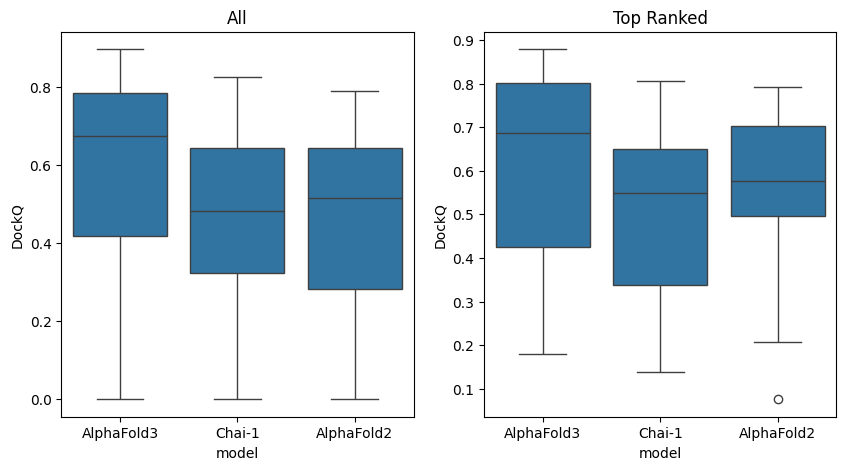

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)

    sns.boxplot(data, x='model', y='DockQ', ax=ax)

plt.show()

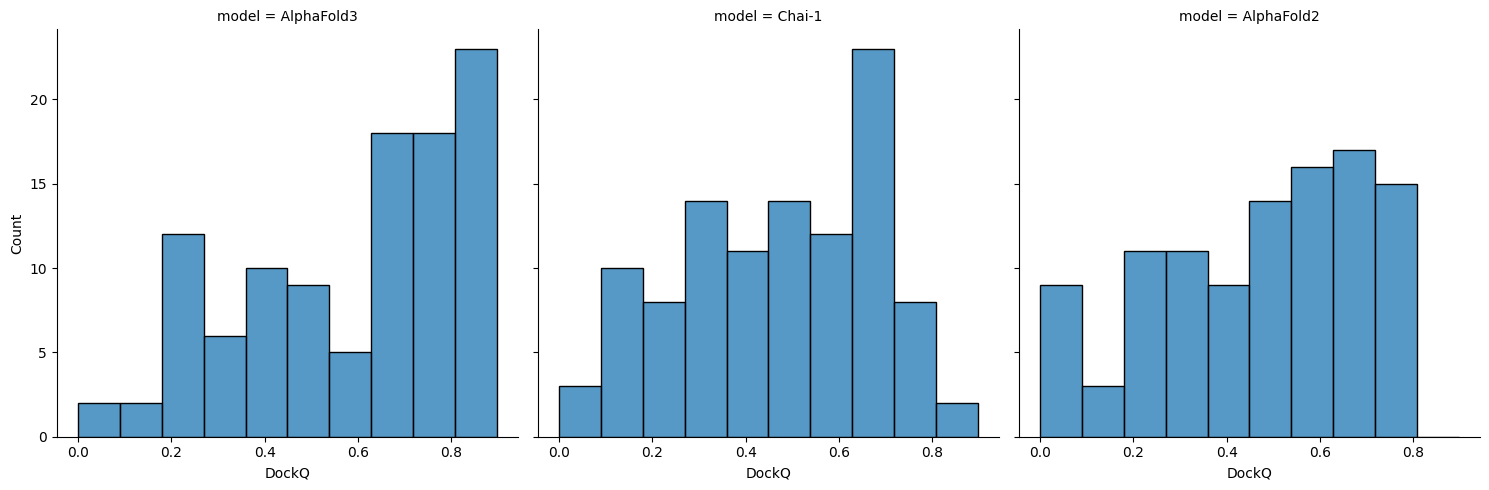

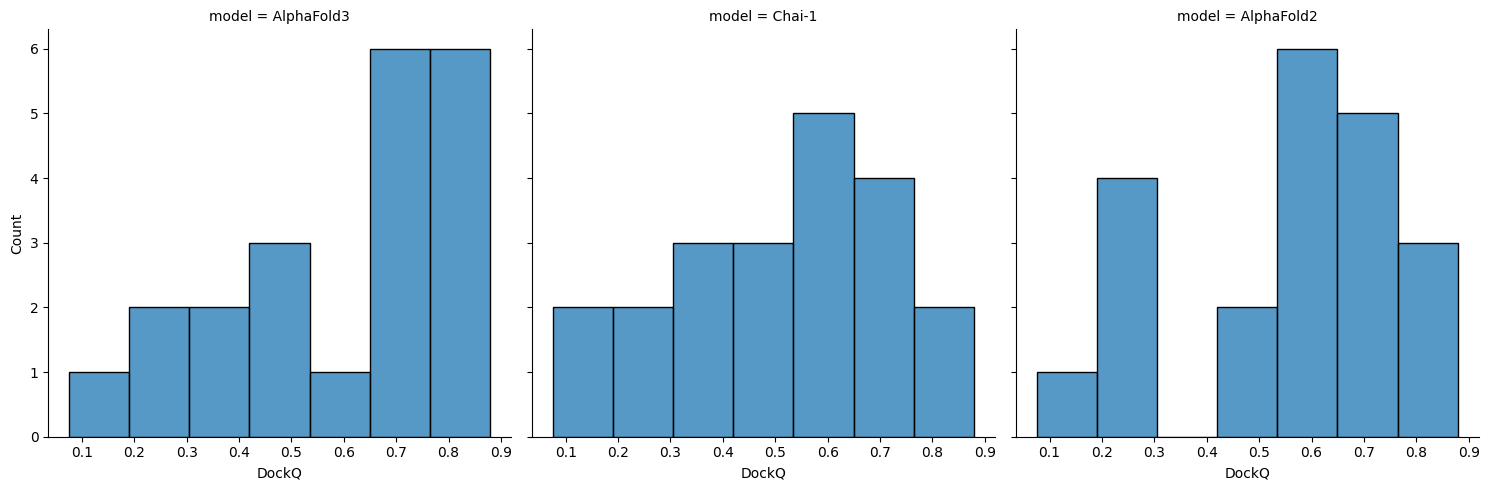

In [23]:
sns.displot(dockq_scores, col='model', x='DockQ', kind='hist')
sns.displot(dockq_scores.query('top_rank'), col='model', x='DockQ', kind='hist')

In [24]:
for title, data in zip(('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    print(title)

    ipy_display.display(pg.anova(data, dv='DockQ', between='model'))

    groups = list(data.groupby('model')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,312,10.579443,0.000036,0.06351


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-3.775482,0.000208,True
1,AlphaFold2,Chai-1,0.197463,0.843658,False
2,AlphaFold3,Chai-1,4.039339,0.000075,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,60,1.085522,0.344265,0.03492


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-0.825443,0.414016,False
1,AlphaFold2,Chai-1,0.646581,0.521596,False
2,AlphaFold3,Chai-1,1.446921,0.155711,False


In [25]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [26]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [27]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    capri_classification = dockq_scores.groupby('model')['capri_classification'].value_counts(normalize=True) * 100
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='model', columns='capri_classification', values='percent'
    )

    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    plot_ax = capri_classification.reindex(columns=order, fill_value=0).plot(
        kind='bar',
        stacked=True,
        color=[colours[col_name] for col_name in order],
        width=0.8,
        edgecolor='none',
        legend=False,
        ax=ax,
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')

    return plot_ax

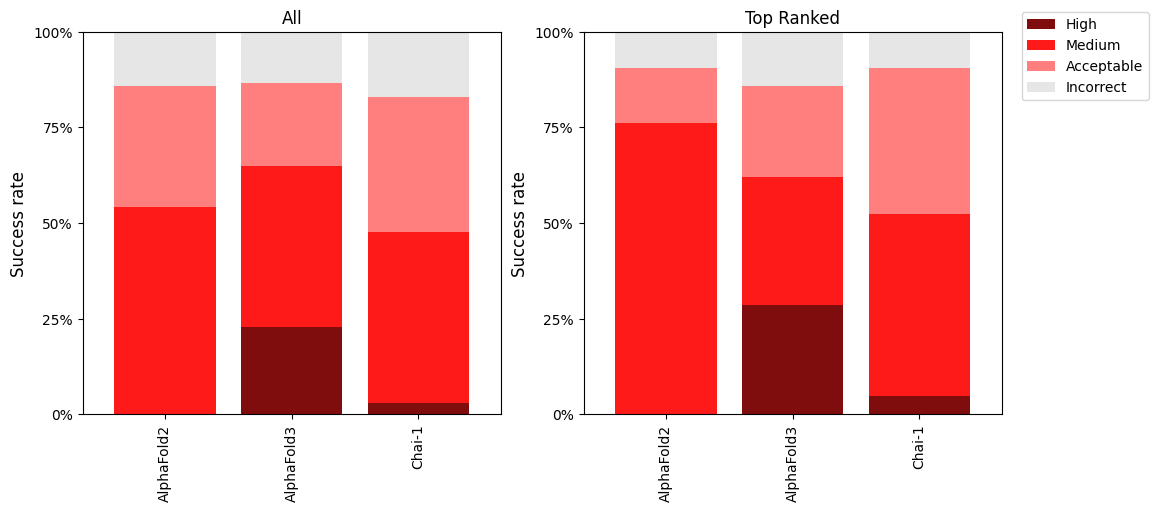

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)
    plot_capri_classification(data, ax=ax)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.show()